# Random Forest for Quantum Magnetometry

In this notebook, we develop a machine learning model to estimate an unknown magnetic field using measurement data generated from a Ramsey quantum sensor. A Ramsey sensor converts the magnetic-field-dependent phase accumulated by a qubit into a measurable probability. By performing measurements at different interrogation times, we obtain a set of measurement probabilities that contain information about the unknown magnetic field.

The aim of this notebook is to train a **Random Forest Regressor** to learn the relationship between these measurement outcomes and the magnetic field.

We will:
1. Load the simulated quantum magnetometry dataset.
2. Separate the measurement features and magnetic-field target.
3. Train a Random Forest regression model.
4. Evaluate its prediction accuracy.
5. Visualize the predicted magnetic field against the true magnetic field.
6. Examine which measurement features contribute most to the predictions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Same sensor parameters as Ramsey Quantum Sensor
GAMMA = 2*np.pi*28e9       
T2 = 1e-3                  

def measurement_prob(B, t, T2=T2, gamma=GAMMA):
    
    phase = gamma*B*t
    visibility = np.exp(-t/T2)

    return 0.5*(1 - visibility*np.cos(phase))

In [2]:
samples = 5000
Bmin = 0
Bmax = 100
interrogation_times_us = np.array([20, 50, 100, 200, 400])
interrogation_times = interrogation_times_us*1e-6
shots = 200
print("Number of samples:", samples)
print("Magnetic field range:", Bmin, "-", Bmax, "nT")
print("Interrogation times (us):", interrogation_times_us)
print("Shots per interrogation time:", shots)

Number of samples: 5000
Magnetic field range: 0 - 100 nT
Interrogation times (us): [ 20  50 100 200 400]
Shots per interrogation time: 200


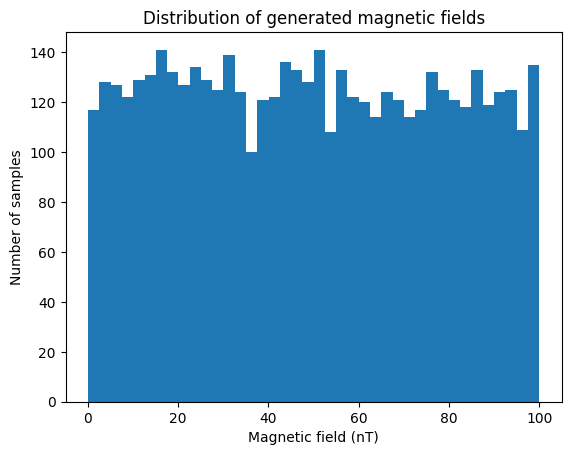

In [3]:
B_values_nT = rng.uniform(Bmin, Bmax, samples)
B_values_T = B_values_nT*1e-9
plt.hist(B_values_nT, bins=40)
plt.xlabel("Magnetic field (nT)")
plt.ylabel("Number of samples")
plt.title("Distribution of generated magnetic fields")
plt.show()

In [4]:
probabilities = measurement_prob(B_values_T[:, None], interrogation_times[None, :])
measurement_counts = rng.binomial(n=shots, p=probabilities)
measurement_frequencies = measurement_counts/shots

print("Probability matrix shape ", probabilities.shape)
print("Measurement matrix shape ", measurement_frequencies.shape)

Probability matrix shape  (5000, 5)
Measurement matrix shape  (5000, 5)


In [5]:
feature_names = [f"P1_{t}us" for t in interrogation_times_us]
dataset = pd.DataFrame(measurement_frequencies, columns=feature_names)
dataset["B_nT"] = B_values_nT
dataset.head(10)

,P1_20us,P1_50us,P1_100us,P1_200us,P1_400us,B_nT
0,0.020,0.140,0.425,0.915,0.285,77.395605
1,0.020,0.070,0.135,0.540,0.810,43.887844
2,0.025,0.190,0.505,0.900,0.175,85.859792
3,0.035,0.075,0.315,0.835,0.455,69.736803
4,0.005,0.020,0.050,0.095,0.280,9.417735
5,0.070,0.190,0.620,0.870,0.225,97.562235
6,0.030,0.135,0.390,0.890,0.325,76.113970
7,0.045,0.135,0.385,0.895,0.215,78.606431
8,0.005,0.025,0.060,0.185,0.290,12.811363
9,0.005,0.055,0.200,0.560,0.865,45.038594


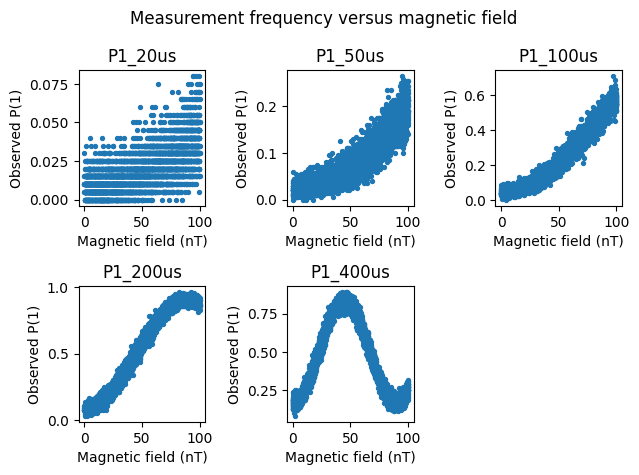

In [12]:
fig, axes = plt.subplots(2, 3)
axes = axes.flatten()

for i, feature in enumerate(feature_names):

    axes[i].scatter(dataset["B_nT"], dataset[feature], s=8)
    axes[i].set_xlabel("Magnetic field (nT)")
    axes[i].set_ylabel("Observed P(1)")
    axes[i].set_title(feature)
axes[-1].axis("off")
plt.suptitle("Measurement frequency versus magnetic field")
plt.tight_layout()
plt.show()

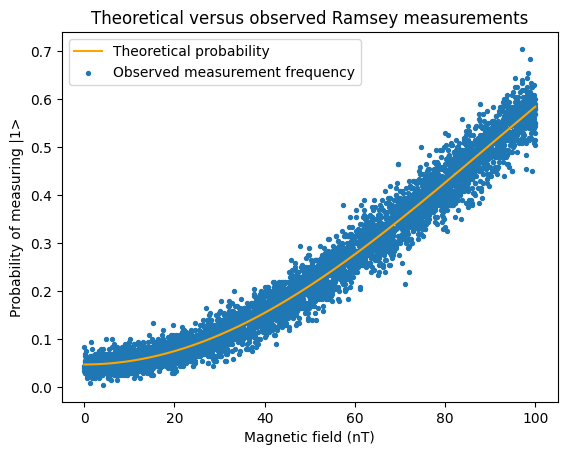

In [13]:
selected_index = 2  
sorted_indices = np.argsort(B_values_nT)
plt.plot(B_values_nT[sorted_indices], probabilities[sorted_indices, selected_index], label="Theoretical probability", color="orange")
plt.scatter(B_values_nT, measurement_frequencies[:, selected_index], s=8, label="Observed measurement frequency")
plt.xlabel("Magnetic field (nT)")
plt.ylabel("Probability of measuring |1>")
plt.title("Theoretical versus observed Ramsey measurements")
plt.legend()
plt.show()

In [14]:
from pathlib import Path

# Create data folder if it doesn't exist
data_folder = Path("../data")
data_folder.mkdir(parents=True, exist_ok=True)

# Save dataset
dataset.to_csv(
    data_folder / "magnetometry_dataset.csv",
    index=False
)

print("Dataset saved successfully!")
print("Location:", data_folder / "magnetometry_dataset.csv")

Dataset saved successfully!
Location: ..\data\magnetometry_dataset.csv
